# A. Data Exploration and Cleaning

## 1. Load the datasets

Load the customer, order and fraud-label files. Preview the records and check
dataset sizes, missing values and data types.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

folder = Path(r"C:\Users\Jaime Ho\Desktop\Y2S2\MLOPS")

customers = pd.read_csv(folder / "customers_base.csv")
orders = pd.read_csv(folder / "orders_base.csv")
labels = pd.read_csv(folder / "labels_base.csv")

C:\Users\Jaime Ho\AppData\Local\Temp\ipykernel_29332\692828910.py:7: DtypeWarning: Columns (0: mobile_verified) have mixed types. Specify dtype option on import or set low_memory=False.
  customers = pd.read_csv(folder / "customers_base.csv")


In [2]:
customers["mobile_verified"] = (
    customers["mobile_verified"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "false": False,
        "1": True,
        "0": False,
        "1.0": True,
        "0.0": False,
        "yes": True,
        "no": False
    })
    .astype("boolean")
)

customers["first_order_datetime"] = pd.to_datetime(
    customers["first_order_datetime"],
    format="mixed",
    errors="coerce",
    utc=True
)

orders["order_date"] = pd.to_datetime(
    orders["order_date"],
    errors="coerce",
    utc=True
)

In [3]:
datasets = {
    "customers": customers,
    "orders": orders,
    "labels": labels
}

for name, df in datasets.items():
    print(f"\n{name}: {df.shape[0]} rows, {df.shape[1]} columns")
    display(df.head())
    display(df.isna().sum().to_frame("Missing values"))


customers: 901312 rows, 9 columns


,country_code,customer_id,mobile_verified,num_orders_last_50days,num_cancelled_orders_last_50days,num_refund_orders_last_50days,total_payment_last_50days,num_associated_customers,first_order_datetime
0,PK,c238e72e73,True,2,1,0,13.190387,1,2021-03-23 09:16:29+00:00
1,MY,d1f64e8f1c,True,8,0,0,41.763437,1,2020-12-01 04:46:26+00:00
2,PH,e0fae59ece,True,3,0,0,44.093079,2,2019-02-13 05:56:40+00:00
3,PK,09af521b9f,True,61,0,1,4925.383520,7,2020-09-08 08:18:39+00:00
4,MY,779dacab15,True,7,0,0,92.428755,1,2021-02-19 09:59:16+00:00


,Missing values
country_code,0
customer_id,0
mobile_verified,0
num_orders_last_50days,0
num_cancelled_orders_last_50days,0
num_refund_orders_last_50days,0
total_payment_last_50days,0
num_associated_customers,0
first_order_datetime,712



orders: 949889 rows, 8 columns


,country_code,order_id,collect_type,payment_method,order_value,num_items_ordered,refund_value,order_date
0,PH,c285aa06a5,Delivery,antfinancial gcash,5.387819,4.0,0.00,2023-04-09 00:00:00+00:00
1,PH,4cd8384425,Delivery,antfinancial gcash,7.452310,6.0,0.00,2023-04-09 00:00:00+00:00
2,PH,aa42f97d2e,Delivery,credit card,15.588588,6.0,0.00,2023-04-09 00:00:00+00:00
3,PH,f3523e5896,Delivery,credit card,90.468361,70.0,0.00,2023-04-09 00:00:00+00:00
4,PH,5ac770f990,Delivery,payment on Delivery,8.123690,6.0,0.88,2023-04-09 00:00:00+00:00


,Missing values
country_code,0
order_id,0
collect_type,0
payment_method,21501
order_value,0
num_items_ordered,1
refund_value,0
order_date,709



labels: 950318 rows, 4 columns


,country_code,order_id,customer_id,is_fraud
0,TH,b9ce4cdead,4a2deee064,0
1,MY,eae640c3dd,0e39f85e6d,0
2,PH,6b5eff4d8f,b88034bb7a,0
3,MY,31928238a7,b24be37d24,0
4,MY,4adec8e335,996287540f,0


,Missing values
country_code,0
order_id,0
customer_id,0
is_fraud,0


### Initial Data Inspection

The output shows each dataset's size, first five records and missing-value counts.

- **Customers:** 901,312 rows and 9 columns containing customer details and historical activity.
- **Orders:** 949,889 rows and 8 columns containing transaction details.
- **Labels:** 950,318 rows and 4 columns linking orders to customers and identifying fraud.

The first five records provide a preview of the fields and their values; they do not represent the full dataset.

The missing-value checks identify:
- **712 missing customer first-order dates**, which prevent customer-age calculations.
- **21,501 missing payment methods**, which will be replaced with `unknown`.
- **One missing item count**, which will be imputed using the training-set median during model preparation.
- **709 missing order dates after initial conversion**, caused by inconsistent date formats rather than missing source dates. These are recovered in Section 8.

The datasets contain different numbers of records, so matching keys must be checked before combining them.

## 2. Handle missing payment methods

The original data contains:
- 712 missing customer first-order dates.
- 21,501 missing payment methods.
- 1 missing item count.

Standardise payment-method text and replace missing values with `unknown`.
Keep missing dates and item counts for later handling rather than inventing values.

In [4]:
def clean_orders(df):
    df = df.copy()
    df["payment_method"] = (
        df["payment_method"]
        .str.strip()
        .str.lower()
        .replace("", pd.NA)
        .fillna("unknown")
    )
    return df

orders = clean_orders(orders)

## 3. Check data validity

Check exact duplicates, repeated record keys, negative numerical values,
fractional item counts and invalid fraud labels.

No issues were found in these checks. Use country code together with the
customer or order ID to identify records.

In [5]:
datasets = {"customers": customers, "orders": orders, "labels": labels}

for name, df in datasets.items():
    print(f"\n{name} — duplicate rows: {df.duplicated().sum()}")
    display(df.dtypes.to_frame("Data type"))


customers — duplicate rows: 0


,Data type
country_code,str
customer_id,str
mobile_verified,boolean
num_orders_last_50days,int64
num_cancelled_orders_last_50days,int64
num_refund_orders_last_50days,int64
total_payment_last_50days,float64
num_associated_customers,int64
first_order_datetime,"datetime64[us, UTC]"



orders — duplicate rows: 0


,Data type
country_code,str
order_id,str
collect_type,str
payment_method,str
order_value,float64
num_items_ordered,float64
refund_value,float64
order_date,"datetime64[us, UTC]"



labels — duplicate rows: 0


,Data type
country_code,str
order_id,str
customer_id,str
is_fraud,int64


### Duplicate Rows and Data Types

- No exact duplicate rows were found in any of the three datasets.
- IDs and categorical fields use string types.
- Customer counts and fraud labels use integer types.
- Payment amounts and order values use floating-point types.
- `mobile_verified` uses a Boolean type.
- Date columns use UTC datetime types, allowing date calculations.
- `num_items_ordered` currently uses a floating-point type. Check for fractional values before converting it to an integer.

These checks support consistent processing, but datetime and Boolean conversions still require validation for unexpected missing values.

In [6]:
keys = {
    "customers": ["country_code", "customer_id"],
    "orders": ["country_code", "order_id"],
    "labels": ["country_code", "order_id"]
}

for name, df in datasets.items():
    repeated = df.duplicated(subset=keys[name], keep=False)
    print(f"{name}: {repeated.sum()} rows with repeated keys")
    display(df.loc[repeated].head())

customers: 0 rows with repeated keys


,country_code,customer_id,mobile_verified,num_orders_last_50days,num_cancelled_orders_last_50days,num_refund_orders_last_50days,total_payment_last_50days,num_associated_customers,first_order_datetime


orders: 0 rows with repeated keys


,country_code,order_id,collect_type,payment_method,order_value,num_items_ordered,refund_value,order_date


labels: 0 rows with repeated keys


,country_code,order_id,customer_id,is_fraud


In [7]:
for name, df in datasets.items():
    numeric = df.select_dtypes(include="number")
    print(f"\n{name} — negative values:")
    display(numeric.lt(0).sum().to_frame("Count"))

items = orders["num_items_ordered"]
print("Fractional item counts:", (items.dropna() % 1 != 0).sum())

print("Invalid fraud labels:",
      (~labels["is_fraud"].dropna().isin([0, 1])).sum())


customers — negative values:


,Count
num_orders_last_50days,0
num_cancelled_orders_last_50days,0
num_refund_orders_last_50days,0
total_payment_last_50days,0
num_associated_customers,0



orders — negative values:


,Count
order_value,0
num_items_ordered,0
refund_value,0



labels — negative values:


,Count
is_fraud,0


Fractional item counts: 0
Invalid fraud labels: 0


### Numerical Validity Checks

- No negative values were found in the numerical columns checked.
- No fractional item counts were found; all non-missing item counts are whole numbers.
- All non-missing fraud labels are valid: `0` for non-fraud and `1` for fraud.

No corrections are needed for these checks. Missing values and unusually large values are assessed separately.

## 4. Explore distributions and class imbalance

The numerical features are strongly right-skewed: most values are small,
while a few are unusually large.

Fraud labels contain approximately 89% non-fraud and 11% fraud records.
Account for this imbalance during model training and evaluation.

,count,mean,std,min,25%,50%,75%,max
num_orders_last_50days,901312.0,21.711433,26.281056,0.0,5.000000,14.000000,29.000000,2162.000000
num_cancelled_orders_last_50days,901312.0,0.264327,1.005042,0.0,0.000000,0.000000,0.000000,259.000000
num_refund_orders_last_50days,901312.0,0.230790,0.856400,0.0,0.000000,0.000000,0.000000,107.000000
total_payment_last_50days,901312.0,302.180567,425.800659,0.0,51.471977,164.582166,394.230368,42569.345127
num_associated_customers,901312.0,2.685398,6.366360,1.0,1.000000,2.000000,3.000000,101.000000


,Skewness
num_orders_last_50days,5.419459
num_cancelled_orders_last_50days,54.998623
num_refund_orders_last_50days,17.515436
total_payment_last_50days,8.676179
num_associated_customers,12.478703


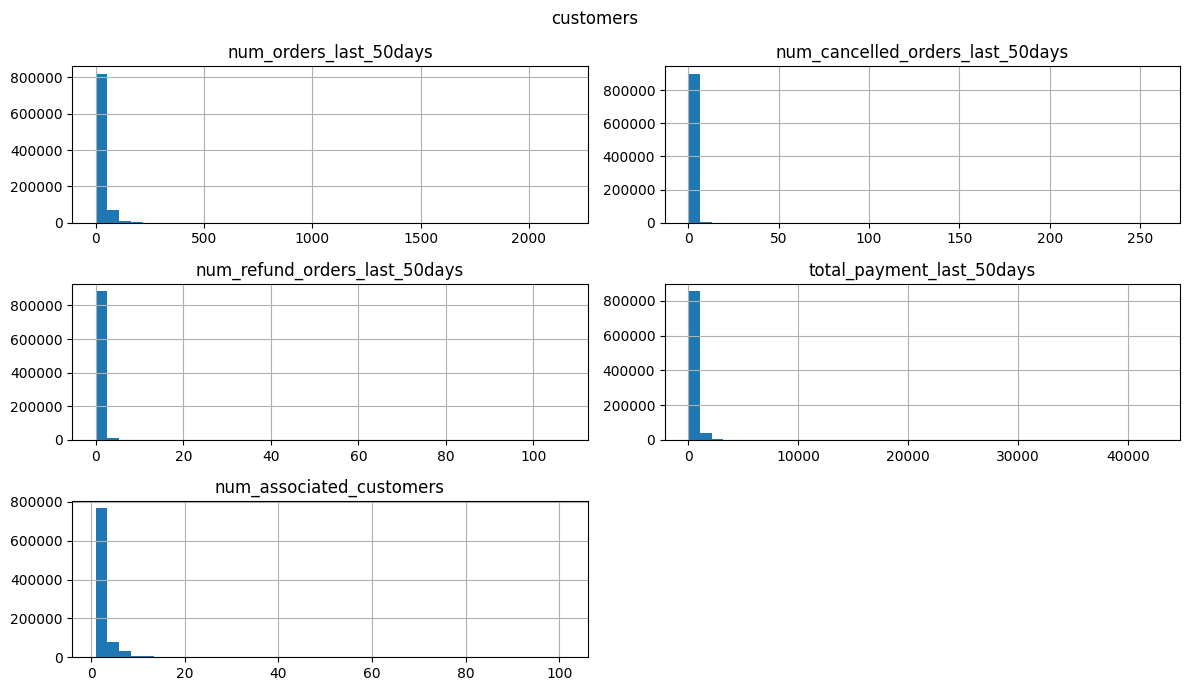

,count,mean,std,min,25%,50%,75%,max
order_value,949889.0,6.938344,6.461997,0.0,3.209875,5.509056,8.511989,662.875105
num_items_ordered,949888.0,3.670441,5.012157,1.0,1.000000,2.000000,4.000000,1600.000000
refund_value,949889.0,2.236194,3.921423,0.0,0.000000,0.930000,2.900000,518.000000


,Skewness
order_value,6.620409
num_items_ordered,41.042020
refund_value,8.409762


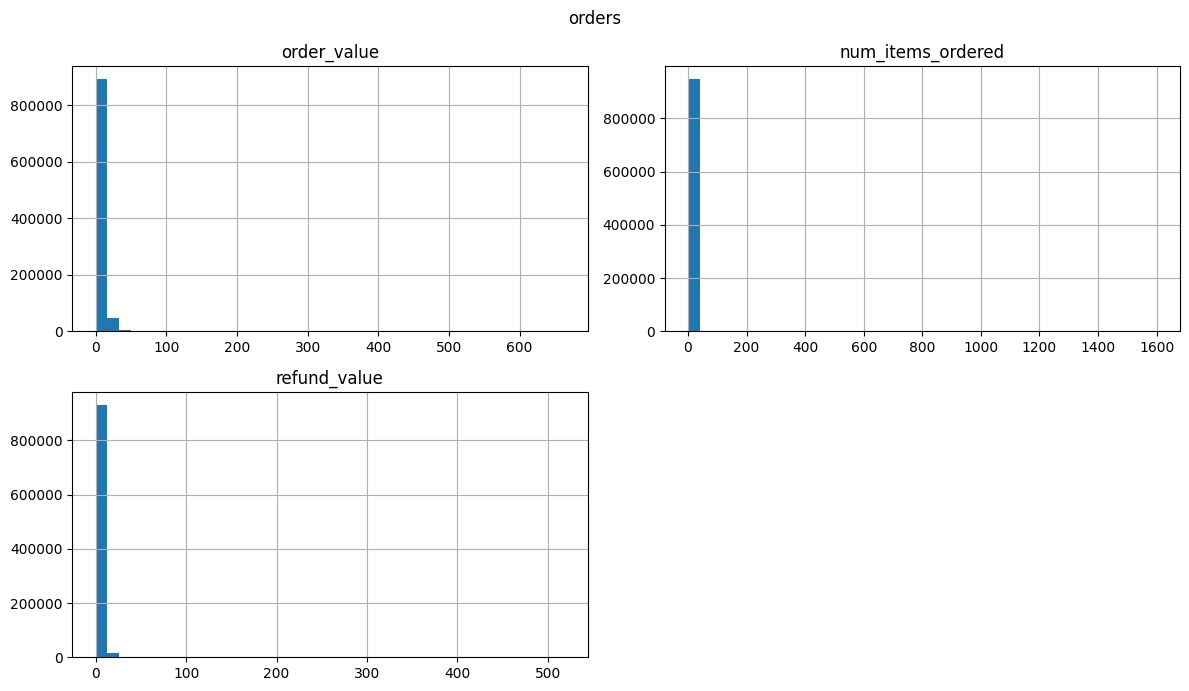

In [8]:
import matplotlib.pyplot as plt

for name, df in {"customers": customers, "orders": orders}.items():
    numeric = df.select_dtypes(include="number")

    display(numeric.describe().T)
    display(numeric.skew().to_frame("Skewness"))

    numeric.hist(bins=40, figsize=(12, 7))
    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

### Distribution of Numerical Features

All eight charts show right-skewed distributions:

- **Orders in the last 50 days:** Most customers place relatively few orders; a few place over 2,000.
- **Cancelled orders:** Most customers have no cancellations; a few have very high counts.
- **Refunded orders:** Most customers have no refunded orders; a few have over 100.
- **Total payment:** Most customers spend relatively small amounts; a few spend over SGD 40,000.
- **Associated customers:** Most customers have few associated accounts; some have around 100.
- **Order value:** Most orders have low values, with a maximum of about SGD 663.
- **Items ordered:** Most orders contain few items, but one contains 1,600.
- **Refund value:** Most refunds are small or zero, with a maximum of SGD 518.

Retain unusual values for investigation and use log features to reduce their scale.

In [9]:
display(
    labels["is_fraud"]
    .value_counts()
    .to_frame("Count")
    .assign(Percentage=lambda x: x["Count"] / x["Count"].sum() * 100)
)

,Count,Percentage
is_fraud,,
0,845814,89.00326
1,104504,10.99674


## 5. Reduce numerical skewness

Apply `log1p` to customer and order numerical features to reduce skewness
and compress extreme values. This transformation supports zeros and retains
the original columns for comparison.

In [10]:
def add_log_features(df, columns):
    df = df.copy()

    for column in columns:
        df[f"{column}_log"] = np.log1p(df[column].astype(float))

    return df

In [11]:
customers = add_log_features(customers, [
    "num_orders_last_50days",
    "num_cancelled_orders_last_50days",
    "num_refund_orders_last_50days",
    "total_payment_last_50days",
    "num_associated_customers"
])

orders = add_log_features(orders, [
    "order_value",
    "num_items_ordered",
    "refund_value"
])

In [12]:
results = []

for table_name, df, columns in [
    ("customers", customers, [
        "num_orders_last_50days",
        "num_cancelled_orders_last_50days",
        "num_refund_orders_last_50days",
        "total_payment_last_50days",
        "num_associated_customers"
    ]),
    ("orders", orders, [
        "order_value",
        "num_items_ordered",
        "refund_value"
    ])
]:
    for column in columns:
        before = df[column].skew()
        after = df[f"{column}_log"].skew()

        results.append({
            "Dataset": table_name,
            "Feature": column,
            "Before": before,
            "After log1p": after,
            "Absolute skewness reduced": abs(after) < abs(before)
        })

display(pd.DataFrame(results).round(3))

,Dataset,Feature,Before,After log1p,Absolute skewness reduced
0,customers,num_orders_last_50days,5.419,-0.403,True
1,customers,num_cancelled_orders_last_50days,54.999,2.643,True
2,customers,num_refund_orders_last_50days,17.515,2.987,True
3,customers,total_payment_last_50days,8.676,-1.007,True
4,customers,num_associated_customers,12.479,2.398,True
5,orders,order_value,6.620,0.092,True
6,orders,num_items_ordered,41.042,1.131,True
7,orders,refund_value,8.410,0.756,True


### Effect of Log Transformation

All eight numerical features show lower absolute skewness after `log1p`.

- **Order value:** skewness falls from 6.620 to 0.092, indicating a nearly symmetric distribution.
- **Items ordered:** skewness falls from 41.042 to 1.131, substantially reducing the influence of extreme quantities.
- **Cancelled orders:** skewness falls from 54.999 to 2.643, although the distribution remains right-skewed.
- **Total payment:** skewness changes from 8.676 to -1.007. The transformation reduces its magnitude but introduces some left skew.

The transformation compresses large values without removing potentially useful fraud signals. Original features remain available for model comparison. Reduced skewness alone does not prove that model performance improves.

## 6. Investigate unusual orders

The largest order contains 1,600 items but costs approximately SGD 6.69.
Another contains 207 items and costs approximately SGD 0.87.

Seven of the ten largest orders are labelled fraud. These observations
require review, but do not prove the values are incorrect.
Retain the records because unusual behaviour may help detect fraud.

In [13]:
display(
    orders.nlargest(10, "num_items_ordered")[
        ["country_code", "order_id", "num_items_ordered", "order_value"]
    ]
)

,country_code,order_id,num_items_ordered,order_value
830063,PK,5794e9f604,1600.0,6.693203
796798,PK,fd8f50b69e,288.0,75.233007
938480,PK,eef45ce3a6,243.0,62.853682
94628,PH,b38d2f5d77,225.0,662.875105
111537,PH,207e437971,220.0,97.670553
826070,PK,35e97975db,207.0,0.873663
300022,BD,50878ef69a,201.0,45.656644
791015,PK,dc70818bee,191.0,47.870030
795098,PK,9abf335583,188.0,13.809499
110128,PH,c522c28b5f,184.0,170.513796


### Orders with the Largest Item Counts

- The largest order contains **1,600 items** but costs only **SGD 6.69**.
- Another order contains **207 items** for **SGD 0.87**.
- These unusually high quantities and low values may indicate data errors or unusual transactions.

Retain these records for investigation. Large item counts alone do not confirm fraud or justify deletion.

In [14]:
largest_orders = orders.nlargest(10, "num_items_ordered")

display(
    largest_orders[
        ["country_code", "order_id", "num_items_ordered", "order_value"]
    ].merge(
        labels[["country_code", "order_id", "is_fraud"]],
        on=["country_code", "order_id"],
        how="left",
        validate="one_to_one"
    )
)

,country_code,order_id,num_items_ordered,order_value,is_fraud
0,PK,5794e9f604,1600.0,6.693203,0
1,PK,fd8f50b69e,288.0,75.233007,1
2,PK,eef45ce3a6,243.0,62.853682,1
3,PH,b38d2f5d77,225.0,662.875105,1
4,PH,207e437971,220.0,97.670553,0
5,PK,35e97975db,207.0,0.873663,0
6,BD,50878ef69a,201.0,45.656644,1
7,PK,dc70818bee,191.0,47.870030,1
8,PK,9abf335583,188.0,13.809499,1
9,PH,c522c28b5f,184.0,170.513796,1


### Class Imbalance

- **845,814 records (89%)** are non-fraud.
- **104,504 records (11%)** are fraud.

A model that always predicts non-fraud would achieve approximately 89% accuracy while detecting no fraud. During modelling, I will compare an unweighted baseline with a model using class weights. I will assess fraud precision, recall, F1-score and PR-AUC alongside accuracy. Any resampling will use training data only.

## 7. Check relationships between datasets

Matching orders and labels by country code and order ID gives:
- 949,874 matching records.
- 444 labels without matching orders.
- 15 orders without matching labels.

Use matching records for supervised training. Exclude unmatched records
from this training dataset; do not interpret missing labels as non-fraud.

Two matched orders have no customer record. Retain these orders and flag
the missing customer information.

In [15]:
for df in [customers, orders, labels]:
    for column in ["country_code", "customer_id", "order_id"]:
        if column in df.columns:
            df[column] = df[column].astype("string").str.strip()

    df["country_code"] = df["country_code"].str.upper()

In [16]:
order_check = orders[["country_code", "order_id"]].merge(
    labels[["country_code", "order_id"]],
    on=["country_code", "order_id"],
    how="outer",
    indicator=True,
    validate="one_to_one"
)

display(order_check["_merge"].value_counts())

_merge
both          949874
right_only       444
left_only         15
Name: count, dtype: int64

In [17]:
matched_orders = orders.merge(
    labels,
    on=["country_code", "order_id"],
    how="inner",
    validate="one_to_one"
)

In [18]:
customer_check = matched_orders.merge(
    customers,
    on=["country_code", "customer_id"],
    how="left",
    validate="many_to_one",
    indicator=True
)

display(customer_check["_merge"].value_counts())

_merge
both          949872
left_only          2
right_only         0
Name: count, dtype: int64

### Dataset Matching Results

- **949,874 orders** match fraud labels and can be used for supervised learning.
- **444 label records** have no matching order.
- **15 orders** have no matching label and are excluded from supervised training rather than treated as non-fraud.
- **Two matched orders** have no customer record. A left join retains these orders, and `customer_record_missing` flags their unavailable customer information.

Country codes and IDs are standardised before merging to prevent formatting differences from causing false mismatches.

In [19]:
data = customer_check.copy()

data["customer_record_missing"] = data["_merge"].eq("left_only")
data = data.drop(columns="_merge")

print("Missing customer records:", data["customer_record_missing"].sum())

Missing customer records: 2


In [20]:
for column in ["first_order_datetime", "num_items_ordered"]:
    data[f"{column}_missing"] = data[column].isna()

In [21]:
missing = data.isna().sum()
display(missing[missing > 0].to_frame("Missing values"))

,Missing values
num_items_ordered,1
order_date,709
num_items_ordered_log,1
mobile_verified,2
num_orders_last_50days,2
num_cancelled_orders_last_50days,2
num_refund_orders_last_50days,2
total_payment_last_50days,2
num_associated_customers,2
first_order_datetime,773


## 8. Standardise date formats

Order dates use different formats, including `2023/04/09`, `2023-03-09`
and `2023/May/06`.

The initial conversion failed for 709 records. Standardising separators
and supporting numeric and abbreviated month names recovered these dates,
leaving no missing order dates.

All non-missing source customer dates could be parsed using mixed-format parsing.
Actual missing customer dates remain missing.

In [22]:
original_orders = pd.read_csv(
    folder / "orders_base.csv",
    dtype="string"
)

parsed_dates = pd.to_datetime(
    original_orders["order_date"],
    errors="coerce"
)

failed = original_orders["order_date"].notna() & parsed_dates.isna()

print("Failed date conversions:", failed.sum())
display(original_orders.loc[failed, ["order_id", "order_date"]].head(10))

Failed date conversions: 709


,order_id,order_date
222458,4bad0780a9,2023-03-09
222459,663dae1a2c,2023-03-09
222460,33b11e83d7,2023-03-09
222461,b186e2e5f6,2023-03-09
222462,18cfb5d4d6,2023-03-09
222463,1556eef92a,2023-03-09
222464,e23967aa06,2023-03-09
222465,b68baf5d35,2023-03-09
222466,50d401efde,2023-03-09
222467,ff2446a16a,2023-03-09


In [23]:
print("Missing customer records:", data["customer_record_missing"].sum())

Missing customer records: 2


In [24]:
def parse_order_dates(series):
    dates = series.str.strip().str.replace("/", "-", regex=False)
    return pd.to_datetime(dates, format="%Y-%m-%d", errors="coerce", utc=True)

date_lookup = original_orders[["country_code", "order_id"]].copy()
date_lookup["order_date"] = parse_order_dates(original_orders["order_date"])

data = data.drop(columns="order_date").merge(
    date_lookup,
    on=["country_code", "order_id"],
    how="left",
    validate="one_to_one"
)

print("Missing order dates:", data["order_date"].isna().sum())

Missing order dates: 509


In [25]:
original_customers = pd.read_csv(
    folder / "customers_base.csv",
    dtype="string"
)

dates = original_customers["first_order_datetime"]

customer_dates = original_customers[["country_code", "customer_id"]].copy()
customer_dates["first_order_datetime"] = pd.to_datetime(
    dates.str.strip(),
    format="mixed",
    errors="coerce",
    utc=True
)

failed = dates.notna() & customer_dates["first_order_datetime"].isna()
print("Unparsed customer dates:", failed.sum())
display(dates[failed].head(10))

Unparsed customer dates: 0


Series([], Name: first_order_datetime, dtype: string)

In [26]:
parsed = parse_order_dates(original_orders["order_date"])

failed = original_orders["order_date"].notna() & parsed.isna()

print("Unparsed source order dates:", failed.sum())
display(original_orders.loc[failed, "order_date"].value_counts().head(10))

Unparsed source order dates: 509


order_date
2023/May/06    95
2023/Mar/21    94
2023/Feb/22    85
2022/Nov/17    53
2022/Dec/14    36
2023/Feb/21    35
2023/Mar/22    20
2022/Nov/16    18
2023/Feb/26    11
2023/Feb/28     7
Name: count, dtype: int64[pyarrow]

In [27]:
def parse_order_dates(series):
    dates = series.str.strip().str.replace("/", "-", regex=False)

    numeric = pd.to_datetime(
        dates, format="%Y-%m-%d", errors="coerce", utc=True
    )
    named = pd.to_datetime(
        dates, format="%Y-%b-%d", errors="coerce", utc=True
    )

    return numeric.fillna(named)

In [28]:
date_lookup = original_orders[["country_code", "order_id"]].copy()
date_lookup["order_date"] = parse_order_dates(original_orders["order_date"])

data = data.drop(columns="order_date").merge(
    date_lookup,
    on=["country_code", "order_id"],
    how="left",
    validate="one_to_one"
)

print("Missing order dates:", data["order_date"].isna().sum())

Missing order dates: 0


## 9. Create date features

Create order month, order day of week and customer age in days.

Compare calendar dates when calculating customer age because order dates
do not include a time. This prevents same-day orders from appearing negative.

The calendar-date check still identified 105 negative customer ages.
Flag these inconsistencies and set the derived age to missing.

- **Order month:** captures possible seasonal patterns.
- **Order day of week:** captures possible weekly patterns.
- **Customer age in days:** measures how long the customer has been active when placing the order.
- **Missing-value flags:** preserve information about unavailable source values.

In [29]:
def create_features(df):
    df = df.copy()

    df["order_day_of_week"] = df["order_date"].dt.dayofweek
    df["order_month"] = df["order_date"].dt.month

    age = (
        df["order_date"].dt.normalize()
        - df["first_order_datetime"].dt.normalize()
    ).dt.days

    df["customer_age_invalid"] = age.lt(0)
    df["customer_age_days"] = age.mask(age.lt(0))

    return df

data = create_features(data)

In [30]:
raw_age = (
    data["order_date"].dt.normalize()
    - data["first_order_datetime"].dt.normalize()
).dt.days

negative = raw_age.lt(0)

print("Orders before first-order calendar date:", negative.sum())

display(
    data.loc[
        negative,
        ["order_date", "first_order_datetime"]
    ].assign(raw_customer_age_days=raw_age.loc[negative]).head()
)

print(
    "Negative ages remaining after cleaning:",
    data["customer_age_days"].lt(0).sum()
)

Orders before first-order calendar date: 105


,order_date,first_order_datetime,raw_customer_age_days
39085,2022-12-19 00:00:00+00:00,2023-01-06 12:00:28+00:00,-18.0
94591,2022-12-29 00:00:00+00:00,2023-01-26 04:41:49+00:00,-28.0
98242,2023-01-06 00:00:00+00:00,2023-01-07 07:13:27+00:00,-1.0
105953,2023-04-17 00:00:00+00:00,2023-04-18 01:10:40+00:00,-1.0
108259,2023-04-21 00:00:00+00:00,2023-04-22 02:28:40+00:00,-1.0


Negative ages remaining after cleaning: 0


## 10. Package the reusable cleaning script

Combine the cleaning and transformation steps into `clean_data.py`.

The `prepare_batch()` function accepts a folder and batch suffix, allowing
PBI 5 to process new customer, order and label files using the same rules.

The script standardises text and dates, converts data types, validates merge
relationships, flags missing values and creates log and date features.

In [31]:
%%writefile clean_data.py
from pathlib import Path
import numpy as np
import pandas as pd


def clean_table(df):
    df = df.copy()

    for column in df.select_dtypes(include=["object", "string"]):
        df[column] = df[column].str.strip().replace("", pd.NA)

    df["country_code"] = df["country_code"].str.upper()
    return df.drop_duplicates()


def parse_order_dates(series):
    dates = series.str.replace("/", "-", regex=False)
    numeric = pd.to_datetime(
        dates, format="%Y-%m-%d", errors="coerce", utc=True
    )
    named = pd.to_datetime(
        dates, format="%Y-%b-%d", errors="coerce", utc=True
    )
    return numeric.fillna(named)


def prepare_batch(folder, batch="base"):
    folder = Path(folder)
    tables = {}

    for name in ["customers", "orders", "labels"]:
        df = pd.read_csv(
            folder / f"{name}_{batch}.csv",
            dtype="string"
        )
        tables[name] = clean_table(df)

    customers, orders, labels = (
        tables["customers"], tables["orders"], tables["labels"]
    )

    orders["payment_method"] = (
        orders["payment_method"].str.lower().fillna("unknown")
    )
    orders["order_date"] = parse_order_dates(orders["order_date"])
    customers["first_order_datetime"] = pd.to_datetime(
        customers["first_order_datetime"],
        format="mixed", errors="coerce", utc=True
    )
    mobile = customers["mobile_verified"].str.lower()

    customers["mobile_verified"] = mobile.map({
        "true": True,
        "false": False,
        "yes": True,
        "no": False,
        "1": True,
        "0": False,
        "1.0": True,
        "0.0": False
    }).astype("boolean")

    unexpected = mobile.notna() & customers["mobile_verified"].isna()

    if unexpected.any():
        raise ValueError(
            "Unexpected mobile_verified values: "
            f"{mobile.loc[unexpected].unique().tolist()}"
        )
        
    labels["is_fraud"] = pd.to_numeric(
        labels["is_fraud"], errors="coerce"
    )

    if not labels["is_fraud"].isin([0, 1]).all():
        raise ValueError("Fraud labels must contain only 0 or 1.")

    labels["is_fraud"] = labels["is_fraud"].astype("int64")
    
    data = orders.merge(
        labels, on=["country_code", "order_id"],
        how="inner", validate="one_to_one"
    ).merge(
        customers, on=["country_code", "customer_id"],
        how="left", validate="many_to_one", indicator=True
    )

    data["customer_record_missing"] = data.pop("_merge").eq("left_only")

    for column in [
        "num_orders_last_50days", "num_cancelled_orders_last_50days",
        "num_refund_orders_last_50days", "total_payment_last_50days",
        "num_associated_customers", "order_value",
        "num_items_ordered", "refund_value"
    ]:
        values = pd.to_numeric(data[column], errors="coerce")
        data[column] = values.mask((values < 0) | ~np.isfinite(values))
        data[f"{column}_missing"] = data[column].isna()
        data[f"{column}_log"] = np.log1p(data[column].astype(float))

    age = (
        data["order_date"].dt.normalize()
        - data["first_order_datetime"].dt.normalize()
    ).dt.days

    data["customer_age_invalid"] = age.lt(0)
    data["customer_age_days"] = age.mask(age.lt(0))
    data["first_order_datetime_missing"] = data["first_order_datetime"].isna()
    data["order_day_of_week"] = data["order_date"].dt.dayofweek
    data["order_month"] = data["order_date"].dt.month

    return data

Writing clean_data.py


In [32]:
import importlib
import clean_data

importlib.reload(clean_data)

folder = r"C:\Users\Jaime Ho\Desktop\Y2S2\MLOPS"
data = clean_data.prepare_batch(folder, batch="base")

print(data.shape)
display(data.head())

(949874, 39)


,country_code,order_id,collect_type,payment_method,order_value,num_items_ordered,refund_value,order_date,customer_id,is_fraud,...,order_value_log,num_items_ordered_missing,num_items_ordered_log,refund_value_missing,refund_value_log,customer_age_invalid,customer_age_days,first_order_datetime_missing,order_day_of_week,order_month
0,PH,c285aa06a5,Delivery,antfinancial gcash,5.387819,4.0,0.0,2023-04-09 00:00:00+00:00,feac69fd6b,1,...,1.854393,False,1.609438,False,0.000000,False,0.0,False,6,4
1,PH,4cd8384425,Delivery,antfinancial gcash,7.45231,6.0,0.0,2023-04-09 00:00:00+00:00,872c90e960,0,...,2.134440,False,1.945910,False,0.000000,False,1358.0,False,6,4
2,PH,aa42f97d2e,Delivery,credit card,15.588588,6.0,0.0,2023-04-09 00:00:00+00:00,bf8e5d99be,0,...,2.808715,False,1.945910,False,0.000000,False,1063.0,False,6,4
3,PH,f3523e5896,Delivery,credit card,90.468361,70.0,0.0,2023-04-09 00:00:00+00:00,39a5fb7406,1,...,4.515993,False,4.262680,False,0.000000,False,631.0,False,6,4
4,PH,5ac770f990,Delivery,payment on delivery,8.12369,6.0,0.88,2023-04-09 00:00:00+00:00,830a7a9aa2,0,...,2.210874,False,1.945910,False,0.631272,False,1409.0,False,6,4


In [33]:
checks = pd.Series({
    "Rows": len(data),
    "Columns": data.shape[1],
    "Duplicate order keys": data.duplicated(
        ["country_code", "order_id"]
    ).sum(),
    "Missing order dates": data["order_date"].isna().sum(),
    "Missing customer records": data["customer_record_missing"].sum(),
    "Missing mobile verification": data["mobile_verified"].isna().sum(),
    "Invalid customer ages flagged": data["customer_age_invalid"].sum(),
    "Negative cleaned customer ages": data["customer_age_days"].lt(0).sum(),
    "Invalid or missing fraud labels": (
        ~data["is_fraud"].isin([0, 1])
    ).sum()
})

display(checks.to_frame("Result"))

missing = data.isna().sum()
display(missing[missing > 0].to_frame("Remaining missing values"))

,Result
Rows,949874
Columns,39
Duplicate order keys,0
Missing order dates,0
Missing customer records,2
Missing mobile verification,2
Invalid customer ages flagged,105
Negative cleaned customer ages,0
Invalid or missing fraud labels,0


,Remaining missing values
num_items_ordered,1
mobile_verified,2
num_orders_last_50days,2
num_cancelled_orders_last_50days,2
num_refund_orders_last_50days,2
total_payment_last_50days,2
num_associated_customers,2
first_order_datetime,773
num_orders_last_50days_log,2
num_cancelled_orders_last_50days_log,2


### Final Data Validation

The cleaned dataset contains **949,874 rows and 39 columns**.

- No duplicate order keys, missing order dates or invalid fraud labels remain.
- **Two orders have no matching customer record**, leaving their customer fields missing.
- **One item count** remains missing from the source data.
- **773 order records** have no customer first-order date. This exceeds the original customer-level count because customers can have multiple orders.
- **105 negative customer ages** were flagged and set to missing, leaving **878 missing customer ages** and no negative cleaned ages.
- Missing original values also remain missing in their corresponding log features.

Missing-value flags preserve information about unavailable data. Remaining missing model inputs will be handled during model preparation, with imputation fitted on **training data only**.

## Summary

The reusable script produced a combined dataset with 949,874 rows and
39 columns.

Key findings and actions:
- Replaced missing payment methods with `unknown`.
- Corrected mixed order-date formats.
- Found no exact duplicates, repeated keys, negative numerical values,
  fractional item counts or invalid fraud labels in the checks.
- Retained unusual orders and created log features to reduce their scale.
- Identified unmatched records and flagged missing customer records.
- Created calendar features and flagged invalid customer ages.

Remaining preparation:
- Fit numerical imputation using training data only.
- Handle missing Boolean values explicitly.
- Address class imbalance during model training.
- Retain unmatched records separately for review.
- Confirm that historical customer features use only information available
  at the time of each order to prevent data leakage.

In [35]:
from pathlib import Path

output_path = Path(
    r"C:\Users\Jaime Ho\Desktop\Y2S2\MLOPS\cleaned_base.csv"
)

data.to_csv(output_path, index=False)

print(f"Cleaned data saved to: {output_path}")

Cleaned data saved to: C:\Users\Jaime Ho\Desktop\Y2S2\MLOPS\cleaned_base.csv
